In [1]:
results = """
=================================================================================================================================================
BUDGET-AWARE MLP-PROB-PRED MCTS EXPERIMENT RESULTS
=================================================================================================================================================
Track               mu   Budget  Trial   Seed   Steps Collision   Laps  Progress Reason         ms/step  p_agg  p_slow  p_feas  Lap times (s)
-------------------------------------------------------------------------------------------------------------------------------------------------
Sepang          1.0000     30ms      1     42    9713 No             2    199.9% done            27.04ms  0.162   0.581   0.257  [194.1s  194.4s]
Sepang          0.9000     30ms      1     42    9718 No             2    199.9% done            27.07ms  0.163   0.580   0.258  [194.5s  194.2s]
Sepang          0.8000     30ms      1     42    9713 No             2    199.9% done            26.87ms  0.163   0.579   0.258  [194.8s  193.7s]
Sepang          0.7000     30ms      1     42    9698 No             2    199.9% done            26.96ms  0.163   0.580   0.257  [193.9s  194.0s]
Sepang          0.6000     30ms      1     42    9670 No             2    199.9% done            27.24ms  0.163   0.579   0.258  [193.6s  193.2s]
Sepang          0.5000     30ms      1     42    9662 No             2    199.9% done            26.96ms  0.163   0.579   0.258  [193.5s  193.0s]
Sepang          0.4000     30ms      1     42    9658 No             2    199.9% done            26.95ms  0.163   0.579   0.258  [193.4s  192.9s]
Sepang          0.3000     30ms      1     42    9649 No             2    199.9% done            26.92ms  0.163   0.579   0.258  [193.2s  192.7s]
Sepang          0.2000     30ms      1     42    9637 No             2    199.9% done            26.85ms  0.163   0.578   0.258  [192.8s  192.7s]
Sepang          0.1000     30ms      1     42    9766 No             2    199.9% done            26.84ms  0.163   0.578   0.259  [195.1s  195.6s]
YasMarina       1.0000     30ms      1     42    7853 No             2    199.9% done            26.87ms  0.163   0.578   0.259  [157.4s  156.7s]
YasMarina       0.9000     30ms      1     42    7862 No             2    199.9% done            27.11ms  0.163   0.578   0.259  [157.6s  156.9s]
YasMarina       0.8000     30ms      1     42    7831 No             2    199.9% done            26.91ms  0.163   0.578   0.259  [156.6s  156.6s]
YasMarina       0.7000     30ms      1     42    7839 No             2    199.9% done            27.19ms  0.163   0.578   0.259  [156.8s  156.8s]
YasMarina       0.6000     30ms      1     42    7848 No             2    199.9% done            27.04ms  0.163   0.579   0.258  [157.3s  156.6s]
YasMarina       0.5000     30ms      1     42    7808 No             2    199.9% done            27.13ms  0.163   0.578   0.259  [156.1s  156.2s]
YasMarina       0.4000     30ms      1     42    7798 No             2    199.9% done            27.03ms  0.163   0.578   0.259  [156.1s  155.8s]
YasMarina       0.3000     30ms      1     42    7824 No             2    199.9% done            26.92ms  0.163   0.578   0.259  [156.4s  156.5s]
YasMarina       0.2000     30ms      1     42    7831 No             2    199.9% done            27.14ms  0.163   0.579   0.258  [156.4s  156.8s]
YasMarina       0.1000     30ms      1     42    2828 YES            0     70.6% collision       27.18ms  0.164   0.575   0.261  []
================================================================================================================================================= 
"""

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

def parse_results(text):
    rows = []
    seen = set()
    for line in text.strip().split("\n"):
        parts = line.split()
        if len(parts) < 7 or parts[0] not in ("Sepang", "YasMarina"):
            continue
        key = (parts[0], parts[1], parts[2], parts[3], parts[4])
        if key in seen:
            continue
        seen.add(key)
        collision = 1 if parts[6] == "YES" else 0
        lap_times = []
        match = re.search(r'\[([^\]]+)\]', line)
        if match and match.group(1).strip():
            lap_times = [float(t.replace('s', '')) for t in match.group(1).split()]
        rows.append({
            "track": parts[0],
            "mu": float(parts[1]),
            "budget": int(parts[2].replace("ms", "")),
            "trial": int(parts[3]),
            "seed": int(parts[4]),
            "collision": collision,
            "lap_times": lap_times,
            "fastest_lap": min(lap_times) if lap_times else np.nan,
            "avg_lap": np.mean(lap_times) if lap_times else np.nan,
        })
    return rows

df = pd.DataFrame(parse_results(results))
print(f"Parsed {len(df)} rows ({df['collision'].sum()} collisions)")
print(f"Tracks: {sorted(df['track'].unique())}")
print(f"Mus: {sorted(df['mu'].unique())}")
print(f"Budgets: {sorted(df['budget'].unique())}")


Parsed 20 rows (1 collisions)
Tracks: ['Sepang', 'YasMarina']
Mus: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Budgets: [30]


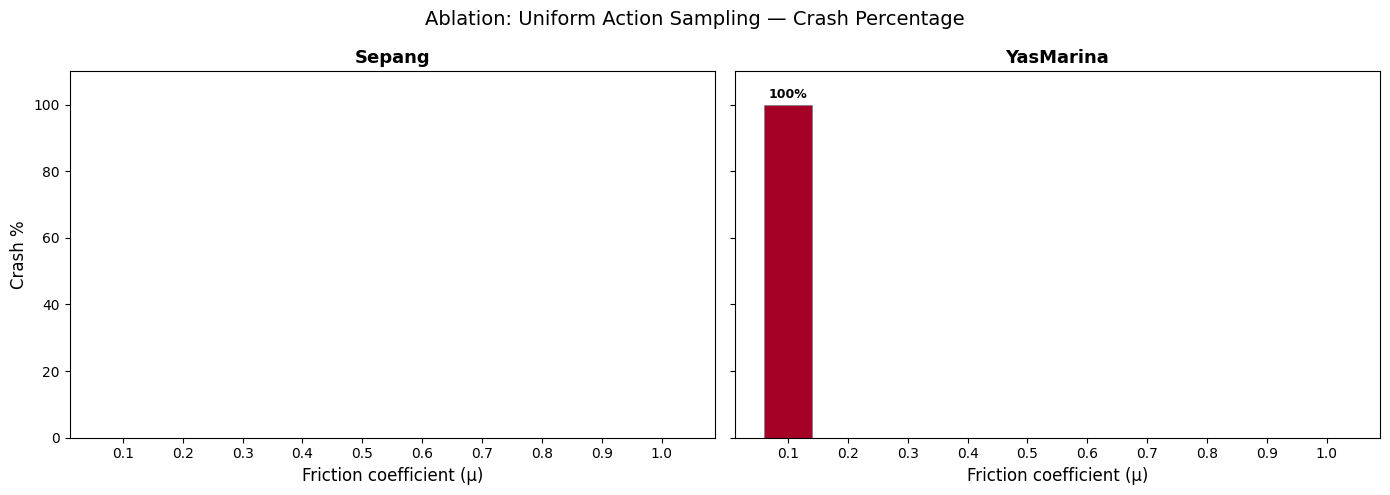

In [3]:
# --- Crash percentage bar chart: one subplot per track ---
crash_pct = df.groupby(["track", "mu"])["collision"].mean() * 100
crash_pct = crash_pct.reset_index().rename(columns={"collision": "crash_pct"})

tracks = sorted(df["track"].unique())
mus = sorted(df["mu"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, track in zip(axes, tracks):
    sub = crash_pct[crash_pct["track"] == track].set_index("mu").reindex(mus).fillna(0)
    colors = plt.cm.RdYlGn_r(sub["crash_pct"].values / 100)
    bars = ax.bar([f"{m:.1f}" for m in mus], sub["crash_pct"].values, color=colors, edgecolor="gray", linewidth=0.5)

    for bar, val in zip(bars, sub["crash_pct"].values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    f"{val:.0f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_xlabel("Friction coefficient (μ)", fontsize=12)
    ax.set_title(f"{track}", fontsize=13, fontweight="bold")
    ax.set_ylim(0, 110)

axes[0].set_ylabel("Crash %", fontsize=12)
fig.suptitle("Ablation: Uniform Action Sampling — Crash Percentage", fontsize=14)
plt.tight_layout()
plt.show()


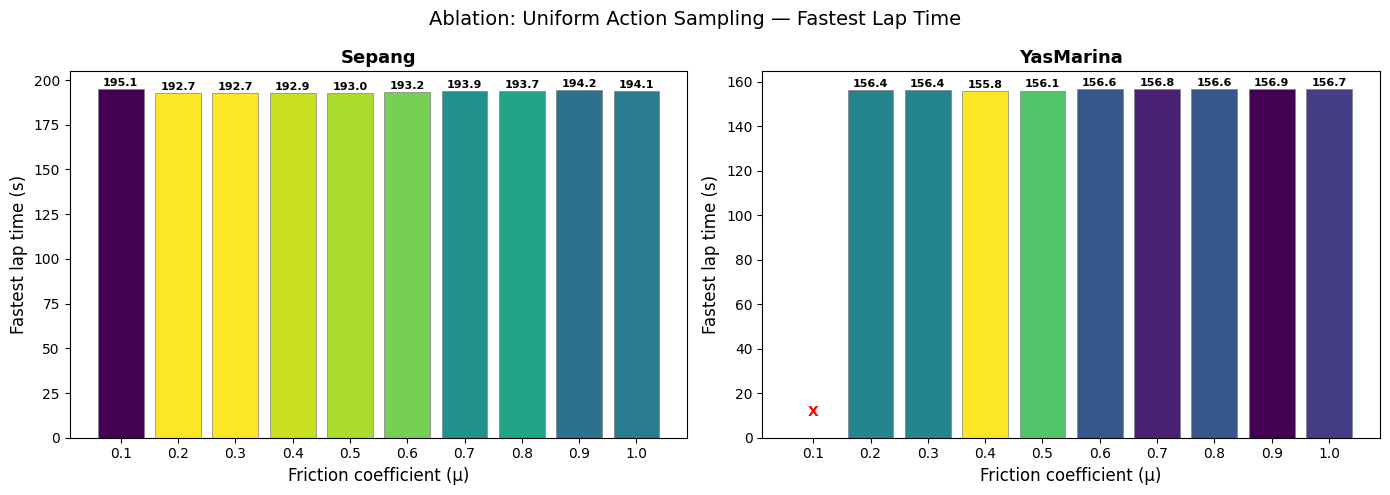

In [4]:
# --- Fastest lap time bar chart: one subplot per track ---
df_ok = df[df["collision"] == 0]

tracks = sorted(df["track"].unique())
mus = sorted(df["mu"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, track in zip(axes, tracks):
    sub = df_ok[df_ok["track"] == track].groupby("mu")["fastest_lap"].mean()
    sub = sub.reindex(mus)

    vals = sub.values.copy()
    valid = ~np.isnan(vals)
    x_labels = [f"{m:.1f}" for m in mus]

    if valid.any():
        vmin, vmax = np.nanmin(vals), np.nanmax(vals)
        norm_vals = np.where(valid, (vals - vmin) / (vmax - vmin + 1e-8), 0)
        colors = [plt.cm.viridis_r(n) if v else (0.9, 0.9, 0.9, 1.0) for n, v in zip(norm_vals, valid)]
    else:
        colors = [(0.9, 0.9, 0.9, 1.0)] * len(mus)

    bar_vals = np.where(valid, vals, 0)
    bars = ax.bar(x_labels, bar_vals, color=colors, edgecolor="gray", linewidth=0.5)

    for bar, val, v in zip(bars, vals, valid):
        if v:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f"{val:.1f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
        else:
            ax.text(bar.get_x() + bar.get_width()/2, ax.get_ylim()[1] * 0.05,
                    "X", ha="center", va="bottom", fontsize=10, fontweight="bold", color="red")

    ax.set_xlabel("Friction coefficient (μ)", fontsize=12)
    ax.set_ylabel("Fastest lap time (s)", fontsize=12)
    ax.set_title(f"{track}", fontsize=13, fontweight="bold")

fig.suptitle("Ablation: Uniform Action Sampling — Fastest Lap Time", fontsize=14)
plt.tight_layout()
plt.show()


In [5]:
# --- Collision details ---
crashed = df[df["collision"] == 1]

if len(crashed) == 0:
    print("No collisions in any configuration!")
else:
    for track in sorted(crashed["track"].unique()):
        sub = crashed[crashed["track"] == track].sort_values(["mu", "seed"])
        grouped = sub.groupby("mu").agg(
            crashes=("collision", "sum"),
            seeds=("seed", lambda s: sorted(s.tolist())),
        ).reset_index()

        print(f"\n{'='*60}")
        print(f"  {track} — mu values with collisions")
        print(f"{'='*60}")
        print(f"  {'mu':>6s}  {'crashes':>7s}   seeds")
        print(f"  {'-'*40}")
        for _, row in grouped.iterrows():
            seeds_str = ", ".join(str(s) for s in row["seeds"])
            print(f"  {row['mu']:6.2f}  {row['crashes']:>7d}     [{seeds_str}]")



  YasMarina — mu values with collisions
      mu  crashes   seeds
  ----------------------------------------
    0.10        1     [42]


In [6]:
# --- LaTeX table rows and crash % printout ---
mus = sorted(df["mu"].unique(), reverse=True)
tracks = sorted(df["track"].unique())
df_ok = df[df["collision"] == 0]

print("Ablation: Uniform Action Sampling — Crash Percentage per mu")
print("=" * 80)

for track in tracks:
    crash = df[df["track"] == track].groupby("mu")["collision"].mean() * 100
    avg = crash.mean()
    print(f"{track:12s}  " + "  ".join([f"μ={m:.1f}: {crash.get(m,0):3.0f}%" for m in mus]) + f"  AVG: {avg:.0f}%")

print()
print("Combined (both maps):")
crash_combined = df.groupby("mu")["collision"].mean() * 100
avg_combined = crash_combined.mean()
print("  " + "  ".join([f"μ={m:.1f}: {crash_combined.get(m,0):3.0f}%" for m in mus]) + f"  AVG: {avg_combined:.0f}%")

print()
print("--- For LaTeX table (copy-paste ready, combined) ---")
row_vals = " & ".join([f"{crash_combined.get(m, 0):.0f}\\%" for m in mus])
print(f"Uniform & {row_vals} & {avg_combined:.0f}\\% \\\\")

print()
print("--- Per track rows ---")
for track in tracks:
    crash = df[df["track"] == track].groupby("mu")["collision"].mean() * 100
    avg = crash.mean()
    row_vals = " & ".join([f"{crash.get(m, 0):.0f}\\%" for m in mus])
    print(f"Uniform ({track}) & {row_vals} & {avg:.0f}\\% \\\\")

print()
print("=" * 80)
print("Fastest Lap per mu")
print("=" * 80)
fastest = df_ok.groupby(["track", "mu"])["fastest_lap"].mean()

for track in tracks:
    vals_str = "  ".join([f"μ={m:.1f}: {fastest.get((track, m), np.nan):5.1f}s" if not np.isnan(fastest.get((track, m), np.nan)) else f"μ={m:.1f}:    --" for m in mus])
    print(f"{track:12s}  {vals_str}")


Ablation: Uniform Action Sampling — Crash Percentage per mu
Sepang        μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1:   0%  AVG: 0%
YasMarina     μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1: 100%  AVG: 10%

Combined (both maps):
  μ=1.0:   0%  μ=0.9:   0%  μ=0.8:   0%  μ=0.7:   0%  μ=0.6:   0%  μ=0.5:   0%  μ=0.4:   0%  μ=0.3:   0%  μ=0.2:   0%  μ=0.1:  50%  AVG: 5%

--- For LaTeX table (copy-paste ready, combined) ---
Uniform & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 50\% & 5\% \\

--- Per track rows ---
Uniform (Sepang) & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% \\
Uniform (YasMarina) & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 0\% & 100\% & 10\% \\

Fastest Lap per mu
Sepang        μ=1.0: 194.1s  μ=0.9: 194.2s  μ=0.8: 193.7s  μ=0.7: 193.9s  μ=0.6: 193.2s  μ=0.5: 193.0s  μ=0.4: 192.9s 